# Segmentierung: Schwellwertverfahren

Ein Schwellwert $t$ teilt jedes Pixel in Objekt oder Hintergrund (wie in der Vorlesung, $L = 256$ Graustufen):

$$s = T(r) = \begin{cases} L-1 & \text{falls } r > t \\ 0 & \text{falls } r \le t \end{cases}$$

$r$ = Grauwert im Eingangsbild, $s$ = Grauwert im Ergebnisbild.

**Wo Sie etwas ergänzen müssen, steht `# TODO`.**

Bild: [Earthrise](https://en.wikipedia.org/wiki/Earthrise), Apollo 8, 1968 (NASA)

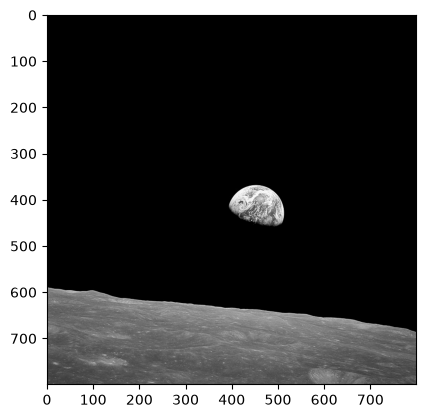

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

L = 256
img = cv2.imread('Earthrise.png', 0)   # 0 = als Graustufenbild laden
plt.imshow(img, cmap='gray')

## 1 Histogramm

Der schwarze Weltraum (Grauwert 0) macht ca. 77 % aller Pixel aus. Damit man den Rest sieht, schneiden wir die y-Achse ab.

Text(0, 0.5, 'Anzahl Pixel')

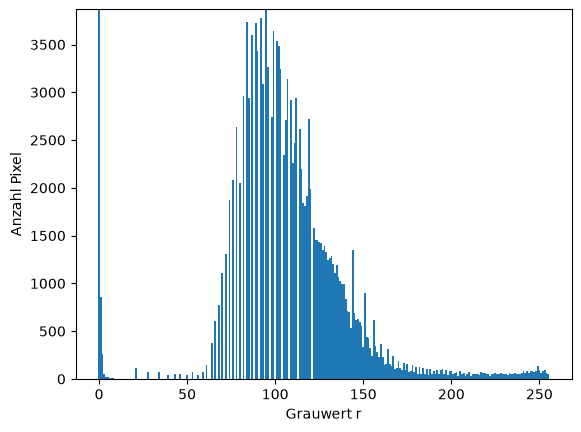

In [2]:
h = np.bincount(img.ravel(), minlength=L)   # h[i] = Anzahl Pixel mit Grauwert i

plt.bar(range(L), h, width=1)
plt.ylim(0, h[1:].max())                     # Balken bei 0 abgeschnitten
plt.xlabel('Grauwert r')
plt.ylabel('Anzahl Pixel')

## 2 Schwellwert selbst programmieren

Setzen Sie die Formel von oben um: alle Pixel mit $r > t$ werden $L-1$, alle anderen $0$.

Tipp: `np.where(bedingung, wert_wenn_ja, wert_wenn_nein)`

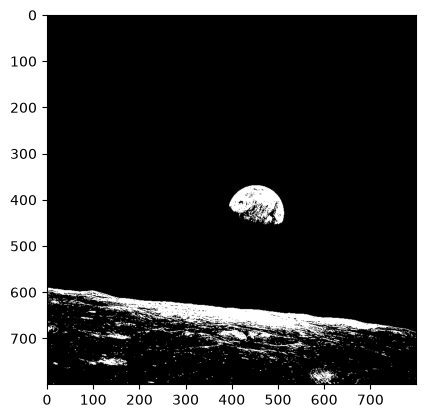

In [4]:
t = 127
img_t = np.where(img > t, L-1, 0)   # TODO: Schwellwert anwenden

plt.imshow(img_t, cmap='gray')

## 3 Schwellwert mit OpenCV

`cv2.threshold(bild, t, L-1, cv2.THRESH_BINARY)` macht genau dasselbe.

**Aufgabe:** Probieren Sie verschiedene $t$ aus.
1. Wo liegt im Histogramm das Tal zwischen den beiden Bergen? Wählen Sie ein $t$ im Tal.
2. Was passiert, wenn $t$ mitten im rechten Berg liegt (z. B. 120 oder 180)?
3. Lässt sich die Erde ohne die Mondoberfläche segmentieren? Warum (nicht)?

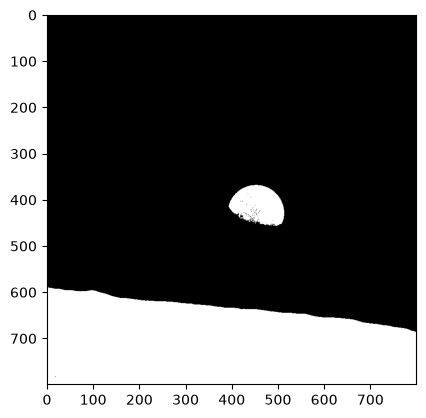

In [12]:
t =  56   # TODO: Schwellwert wählen
_, img_t = cv2.threshold(img, t, L-1, cv2.THRESH_BINARY)

plt.imshow(img_t, cmap='gray')

*Ihre Antworten:*

1. 
2. 
3. 

## 4 Otsu-Verfahren

Otsu probiert **alle** $t$ durch und gibt jedem eine Note. Das $t$ mit der besten Note gewinnt.

1. Normiertes Histogramm: $p(i) = \dfrac{n_i}{n}$ (Anteil der Pixel mit Grauwert $i$)
2. Für jedes $t$:
   - Anteil dunkler / heller Pixel: $P_1 = \sum_{i=0}^{t} p(i)$, $\quad P_2 = 1 - P_1$
   - mittlerer Grauwert dunkel / hell: $m_1 = \dfrac{1}{P_1}\sum_{i=0}^{t} i\,p(i)$, $\quad m_2 = \dfrac{1}{P_2}\sum_{i=t+1}^{L-1} i\,p(i)$
3. Note: $\sigma_B^2(t) = P_1\,P_2\,(m_1 - m_2)^2$
4. Ergebnis: $t^* =$ das $t$ mit dem größten $\sigma_B^2$

Tipp: `p[:t+1]` sind die Werte $p(0) \dots p(t)$, `p[t+1:]` der Rest.

In [11]:
p = np.bincount(img.ravel(), minlength=L) / img.size   # Schritt 1: p(i)
i = np.arange(L)                                       # alle Grauwerte 0 ... L-1
sigma_B = np.zeros(L)

for t in range(L - 1):                                 # Schritt 2: jedes mögliche t
    P1 = np.sum(p[:t+1])   # TODO: Anteil dunkler Pixel
    P2 = np.sum(p[t+1:])   # TODO: Anteil heller Pixel
    if P1 == 0 or P2 == 0:                             # eine Klasse leer -> überspringen
        continue
    m1 = np.sum(i[:t+1] * p[:t+1]) / P1   # TODO: mittlerer Grauwert dunkel
    m2 = np.sum(i[t+1:] * p[t+1:]) / P2   # TODO: mittlerer Grauwert hell
    sigma_B[t] = P1 * P2 * (m1 - m2)**2   # TODO: Schritt 3, Note für dieses t

t_otsu = np.argmax(sigma_B)   # TODO: Schritt 4 (Tipp: np.argmax)
print('Otsu:', t_otsu)

Otsu: 56


Vergleich mit OpenCV (`cv2.THRESH_OTSU` berechnet $t$ selbst, der übergebene Wert 0 wird ignoriert) und Note für jedes $t$:

OpenCV: 56.0


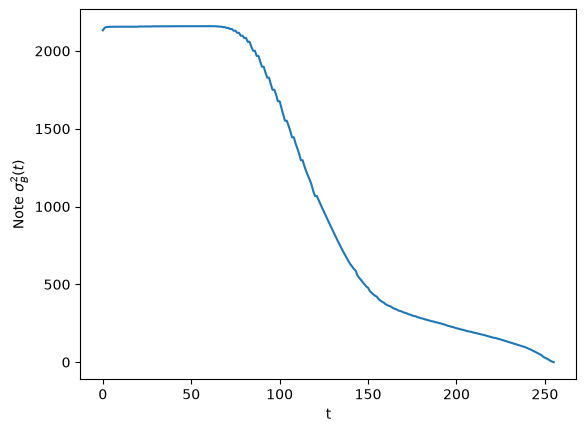

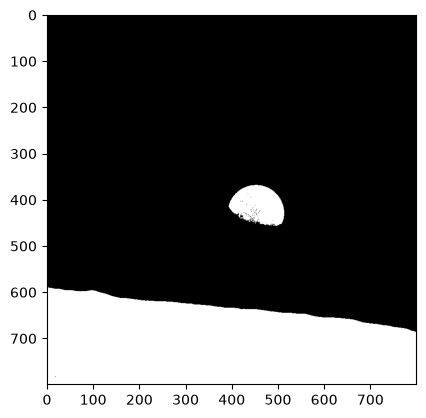

In [13]:
t_cv, img_otsu = cv2.threshold(img, 0, L-1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('OpenCV:', t_cv)

plt.plot(sigma_B)
plt.xlabel('t'); plt.ylabel('Note $\\sigma_B^2(t)$')
plt.show()
plt.imshow(img_otsu, cmap='gray')

## 5 Ungleichmäßige Ausleuchtung: Shading-Korrektur

Bild: Neumann, *Bildverarbeitung für Einsteiger*

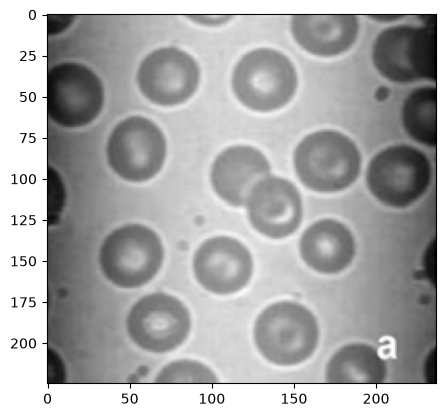

In [45]:
img = cv2.imread('zellen.png', 0)
plt.imshow(img, cmap='gray')

**Aufgabe:** Wählen Sie ein $t$, sodass möglichst nur die Zellen zu sehen sind. Warum klappt das nicht überall?

In [46]:
p = np.bincount(img.ravel(), minlength=L) / img.size   # Schritt 1: p(i)
i = np.arange(L)                                       # alle Grauwerte 0 ... L-1
sigma_B = np.zeros(L)

for t in range(L - 1):                                 # Schritt 2: jedes mögliche t
    P1 = np.sum(p[:t+1])   # TODO: Anteil dunkler Pixel
    P2 = np.sum(p[t+1:])   # TODO: Anteil heller Pixel
    if P1 == 0 or P2 == 0:                             # eine Klasse leer -> überspringen
        continue
    m1 = np.sum(i[:t+1] * p[:t+1]) / P1   # TODO: mittlerer Grauwert dunkel
    m2 = np.sum(i[t+1:] * p[t+1:]) / P2   # TODO: mittlerer Grauwert hell
    sigma_B[t] = P1 * P2 * (m1 - m2)**2   # TODO: Schritt 3, Note für dieses t

t_otsu = np.argmax(sigma_B)   # TODO: Schritt 4 (Tipp: np.argmax)
print('Otsu:', t_otsu)

Otsu: 156


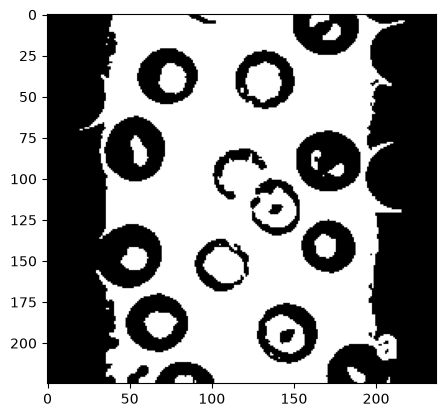

In [38]:
t = 156   # TODO: Schwellwert wählen
_, img_t = cv2.threshold(img, t, L-1, cv2.THRESH_BINARY)
plt.imshow(img_t, cmap='gray')

Jetzt mit Shading-Korrektur:

1. Hintergrund $h$ schätzen: Mittelwertfilter, viel größer als die Zellen (31 × 31) → `cv2.blur(bild, (31, 31))`
2. Bild durch Hintergrund teilen: $f_\text{korr} = f / h$
3. Wieder auf $[0, L-1]$ bringen: $f_\text{korr} = (L-1)\cdot\dfrac{f_\text{korr} - \min}{\max - \min}$
4. Schwellwert anwenden

Text(0.5, 1.0, 'Ergebnis')

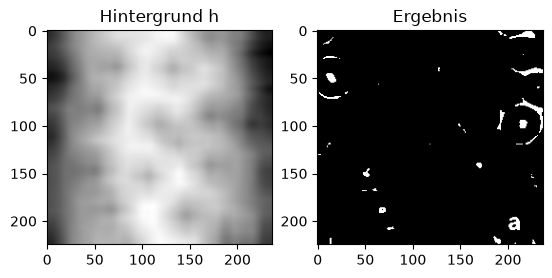

In [43]:
h = cv2.blur(img, (31, 31))        # TODO: Schritt 1
f_korr = img / h   # TODO: Schritt 2
f_korr = (L-1)*((f_korr - f_korr.min()) / (f_korr.max() - f_korr.min()))   # TODO: Schritt 3

t = 156     # TODO: Schritt 4
_, img_t = cv2.threshold(f_korr, t, L-1, cv2.THRESH_BINARY)

plt.subplot(1, 2, 1); plt.imshow(h, cmap='gray'); plt.title('Hintergrund h')
plt.subplot(1, 2, 2); plt.imshow(img_t, cmap='gray'); plt.title('Ergebnis')

Text(0.5, 1.0, 'Ergebnis')

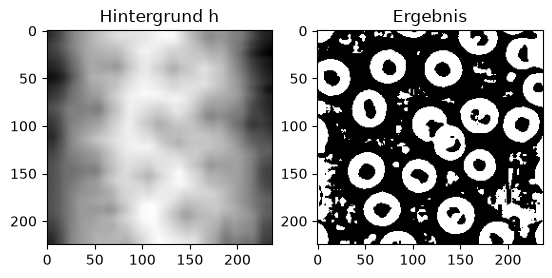

In [47]:
h = cv2.blur(img, (31, 31))        # TODO: Schritt 1
f_korr = img - h   # TODO: Schritt 2
f_korr = np.clip(f_korr, 0, L-1)   # TODO: Schritt 3

t = 156     # TODO: Schritt 4
_, img_t = cv2.threshold(f_korr, t, L-1, cv2.THRESH_BINARY)

plt.subplot(1, 2, 1); plt.imshow(h, cmap='gray'); plt.title('Hintergrund h')
plt.subplot(1, 2, 2); plt.imshow(img_t, cmap='gray'); plt.title('Ergebnis')

## 6 Zusatzaufgabe: Farbbild (Wüsten segmentieren)

Bild: [The Blue Marble](https://en.wikipedia.org/wiki/The_Blue_Marble), Apollo 17, 1972 (NASA)

Im HSV-Farbraum steckt die Farbe im H-Kanal (0 … 179), die Helligkeit im V-Kanal.
1. Erdmaske aus V (Weltraum entfernen)
2. Wolken aus V (sehr hell)
3. Wüsten: rötlich-braune Farbtöne, also H nahe 0 bzw. nahe 179 → `cv2.inRange`
4. Masken kombinieren: Wüste UND Erde UND NICHT Wolke

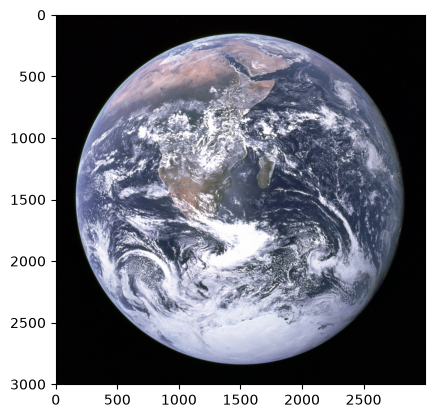

In [ ]:
img = cv2.imread('The_Blue_Marble.png')[:, :, ::-1]   # BGR -> RGB
img_hsv = cv2.cvtimg_hsv[:, :, 0]Color(img, cv2.COLOR_RGB2HSV)
H, V = , img_hsv[:, :, 2]
plt.imshow(img)

In [ ]:

_, erde = 0     # TODO: Schritt 1, Schwellwert auf V
_, wolken =    # TODO: Schritt 2, Schwellwert auf V
wueste = cv2.inRange(H, 0, 20) | cv2.inRange(H, 150, 179)      # TODO: Schritt 3, z. B. cv2.inRange(H, 0, 20) | cv2.inRange(H, 150, 179)

ergebnis = wueste & erde & ~wolken   # Schritt 4
plt.imshow(ergebnis, cmap='gray')

ValueError: too many values to unpack (expected 2)